In [ ]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import pandas as pd
import torch


device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")


class CRNetwork(gym.Env):
    metadata = {"render_modes": []}

    def __init__(
        self, n_ST=2, noise=1e-6, int_thresh=-28.0,
        max_power=10e-3, steps_per_run=100, dtype=np.float32, seed=None,
        interference_reference_w=1.0, error_variance=0.1, hist_len = 1,
        reward_mode="paper", alpha=0.2,beta=10.0):
        super().__init__()

        if not isinstance(n_ST, (int, np.integer)) or n_ST < 1:
            raise ValueError("n_ST must be a positive integer.")
        if not isinstance(steps_per_run, (int, np.integer)) or steps_per_run < 1:
            raise ValueError("steps_per_run must be a positive integer.")
        if not np.issubdtype(np.dtype(dtype), np.floating):
            raise ValueError("Use a floating-point observation dtype.")

        parameters = (noise, int_thresh, max_power, interference_reference_w)
        if not np.all(np.isfinite(parameters)):
            raise ValueError("Environment parameters must be finite.")
        if noise <= 0 or max_power <= 0 or interference_reference_w <= 0:
            raise ValueError("Noise, power budget, and interference reference must be positive.")
        if not np.isfinite(error_variance) or error_variance < 0:
            raise ValueError("error_variance must be finite and nonnegative.")
        if not np.isfinite(alpha) or not 0 <= alpha <= 1:
            raise ValueError("alpha must be between 0 and 1.")
        if not np.isfinite(beta) or beta < 0:
            raise ValueError("beta must be finite and nonnegative.")

        self.k = int(n_ST)
        self.N0 = float(noise)
        self.Pmax = float(max_power)
        self.Ith = float(10**(int_thresh / 10))

        if not np.isfinite(self.Ith) or self.Ith <= 0:
            raise ValueError("Converted interference threshold must be finite and positive.")

        self.max_steps = int(steps_per_run)
        self.dtype = np.dtype(dtype)

        self.hist_len = int(hist_len)
        assert self.hist_len >= 1
        self.obs_dim = (self.hist_len + 1) * self.k + 1
        self.action_dim = self.k

        self.error_variance = float(error_variance)
        self.beta = float(beta)
        self.alpha = float(alpha)

        self.reward_mode = "paper" if reward_mode == "paper" else "custom"

        self.observation_space = spaces.Box(
            low=-np.inf,
            high=np.inf,
            shape=(self.obs_dim,),
            dtype=self.dtype
        )
        self.action_space = spaces.Box(
            low=-1.0,
            high=1.0,
            shape=(self.k,),
            dtype=self.dtype
        )

        # Random number generator
        self.np_random = np.random.default_rng(seed)
        self.step_count = 0
        self._needs_reset = True

    def get_channel_gain(self, update=True):

        # Update complex channel coefficients only when requested
        if update:
           # Noisy estimate
            w_p = (self.np_random.standard_normal(self.k) + 1j * self.np_random.standard_normal(self.k)) / np.sqrt(2)
            w_s = (self.np_random.standard_normal(self.k)+ 1j * self.np_random.standard_normal(self.k)) / np.sqrt(2)

            # Temporally correlated ST-PR channels
            self.hint = ((1 - self.alpha) * self.hint + np.sqrt(2 * self.alpha - self.alpha**2) * w_p)
            self.hsr = ((1 - self.alpha) * self.hsr + np.sqrt(2 * self.alpha - self.alpha**2) * w_s)
        # Actual channel power gains
        g_pr_actual = np.abs(self.hint)**2
        g_sr = np.abs(self.hsr)**2
        # Imperfect CSI on ST-PR links only
        error = np.sqrt(self.error_variance / 2) * (self.np_random.standard_normal(self.k) + 1j * self.np_random.standard_normal(self.k))

        hpr_est = self.hint + error
        gpr_est = np.abs(hpr_est)**2
        self.hpr_est = hpr_est

        return g_pr_actual, gpr_est, g_sr

    def _observation(self):
        # return np.concatenate(
        #     [self.hint_est, self.P_prev, [self.r_prev]]
        # ).astype(self.dtype)
        return np.concatenate([self.est_hist.ravel(), self.P_prev, [self.r_prev]]).astype(self.dtype)

    def reset(self, *, seed=None, options=None):

        super().reset(seed=seed)

        self.step_count = 0
        self.P_prev = np.zeros(self.k)
        self.r_prev = 0.0

        # Initialize complex channel coefficients
        self.hint = (self.np_random.standard_normal(self.k) + 1j * self.np_random.standard_normal(self.k)) / np.sqrt(2)

        self.hsr = (self.np_random.standard_normal(self.k) + 1j * self.np_random.standard_normal(self.k)) / np.sqrt(2)

        # Initial channel gains and imperfect CSI
        self.g_pr_actual, self.hint_est, self.g_sr = (self.get_channel_gain(update=False))
        self.est_hist = np.tile(self.hint_est, (self.hist_len, 1))   # pad history with the current estimate

        self._needs_reset = False

        return self._observation(), {}

    def step(self, action):

        if self._needs_reset:
            raise RuntimeError("Call reset() before stepping or after an episode ends.")

        action = np.asarray(action, dtype=np.float64)

        if action.shape != (self.k,) or not np.all(np.isfinite(action)):
            raise ValueError(f"Expected a finite action with shape ({self.k},).")

        raw_action = np.clip(action, -1.0, 1.0)

        # Action-to-power mapping
        fractions = (raw_action + 1.0) / 2.0
        powers = fractions * self.Pmax

        # Capacity using actual desired channel gains
        signal_power = powers * self.g_sr
        snr = signal_power / self.N0
        capacity = np.log2(1.0 + snr)

        # Actual primary interference
        interference = float(np.sum(powers * self.g_pr_actual))

        normalized_violation = max(
            0.0,
            (interference - self.Ith) / self.Ith
        )

        power_ok = bool(
            np.all(powers >= 0) and np.all(powers <= self.Pmax)
        )

        feasible = bool(interference <= self.Ith and power_ok)

        # Reward calculation
        if self.reward_mode == "paper":
            reward = float(capacity.sum()) if feasible else -interference
        else:
            reward = float(capacity.sum()) - self.beta * normalized_violation

        info = {
            "capacity": capacity.copy(),
            "snr": snr.copy(),
            "interference": interference,
            "constraints_satisfied": feasible,
            "allocation_fractions": fractions.copy(),
            "transmit_powers": powers.copy(),
            "actual_interference_gains": self.g_pr_actual.copy(),
            "desired_gains": self.g_sr.copy(),
            "estimated_interference": float(np.sum(powers * self.hint_est)),
            "normalized_excess": float(normalized_violation),
            "penalty": float(self.beta * normalized_violation),
            "actual_violation": bool(interference > self.Ith),
            "estimated_violation": bool(np.sum(powers * self.hint_est) > self.Ith),
        }
        # Store previous action and reward
        self.P_prev = powers.copy()
        self.r_prev = reward

        self.step_count += 1

        terminated = False
        truncated = bool(self.step_count >= self.max_steps)

        # Generate next channel realization for the next observation
        self.g_pr_actual, self.hint_est, self.g_sr = (self.get_channel_gain(update=True))
        self.est_hist = np.vstack([self.hint_est, self.est_hist[:-1]])  # newest first

        self._needs_reset = truncated

        return self._observation(), reward, terminated, truncated, info


In [ ]:
import numpy as np
import torch
from torch import nn
from torch.distributions import Normal


class RolloutBuffer:
    def __init__(self):
        self.actions = []
        self.states = []
        self.logprobs = []
        self.rewards = []
        self.state_values = []
        self.is_terminals = []

    def clear(self):
        self.actions.clear()
        self.states.clear()
        self.logprobs.clear()
        self.rewards.clear()
        self.state_values.clear()
        self.is_terminals.clear()


def compute_gae(rewards, values, next_values, dones, gamma, lam):
    """Generalised advantage estimation (numpy, no torch, so it can be unit-tested).

    rewards[t], values[t] = V(s_t), next_values[t] = value used to bootstrap after step t
    (0 for a true termination, V(s_{t+1}) otherwise, INCLUDING at a time-limit truncation),
    dones[t] = the episode ended at step t (terminated OR truncated).

    delta_t = r_t + gamma * next_values[t] - values[t]
    A_t     = delta_t + gamma * lam * (1 - dones[t]) * A_{t+1}
    The bootstrap is kept at a truncation; only the advantage CHAIN is cut at an episode boundary.
    """
    T = len(rewards)
    adv = np.zeros(T, dtype=np.float64)
    gae = 0.0
    for t in reversed(range(T)):
        delta = rewards[t] + gamma * next_values[t] - values[t]
        gae = delta + gamma * lam * (1.0 - float(dones[t])) * gae
        adv[t] = gae
    return adv


class PPO:


    def __init__(
        self,
        state_dim,
        action_dim,
        actor_lr=3e-4,
        critic_lr=3e-4,
        gamma=0.0,
        gae_lambda=0.95,
        eps_clip=0.2,
        K_epochs=10,
        action_std=0.3,           # INITIAL std (now learned / scheduled)
        entropy_coef=0.0,
        minibatch_size=None,
        target_kl=None,           # e.g. 0.02 stops the epochs early if the policy moved too far
        init_bias=None,           # e.g. -0.7 starts the actor near a low power (tanh(-0.7) ~ -0.6)
        min_std=0.01,
        max_std=1.0,
        device=None,
        buffer=None,
    ):
        self.device = torch.device(
            device or ("cuda" if torch.cuda.is_available() else "cpu")
        )

        self.gamma = gamma
        self.gae_lambda = gae_lambda
        self.eps_clip = eps_clip
        self.K_epochs = K_epochs
        self.entropy_coef = entropy_coef
        self.minibatch_size = minibatch_size
        self.target_kl = target_kl

        self.buffer = RolloutBuffer() if buffer is None else buffer
        self.next_values = []
        self.last_update_stats = {}

        self.actor = nn.Sequential(
            nn.Linear(state_dim, 64), nn.ReLU(),
            nn.Linear(64, 64), nn.ReLU(),
            nn.Linear(64, action_dim),
        ).to(self.device)

        self.critic = nn.Sequential(
            nn.Linear(state_dim, 64), nn.ReLU(),
            nn.Linear(64, 64), nn.ReLU(),
            nn.Linear(64, 1),
        ).to(self.device)

        if init_bias is not None:
            with torch.no_grad():
                self.actor[-1].bias.fill_(float(init_bias))


        self.log_std = nn.Parameter(
            torch.full((action_dim,), float(np.log(action_std)), device=self.device)
        )
        self.min_log_std = float(np.log(min_std))
        self.max_log_std = float(np.log(max_std))

        self.actor_optimizer = torch.optim.Adam(
            [{"params": self.actor.parameters()}, {"params": [self.log_std]}],
            lr=actor_lr,
        )
        self.critic_optimizer = torch.optim.Adam(
            self.critic.parameters(), lr=critic_lr
        )


    def tensor(self, data):
        return torch.as_tensor(
            np.asarray(data), dtype=torch.float32, device=self.device
        )

    def _dist(self, states):
        return Normal(self.actor(states), self.log_std.exp())

    def _clamp_log_std(self):
        with torch.no_grad():
            self.log_std.clamp_(min=self.min_log_std, max=self.max_log_std)


    @torch.no_grad()
    def choose_action(self, state, deterministic=False):
        state_tensor = self.tensor(state)
        distribution = self._dist(state_tensor)

        raw_action = distribution.mean if deterministic else distribution.sample()
        action = torch.tanh(raw_action)
        logprob = distribution.log_prob(raw_action).sum(dim=-1)

        return action.cpu().numpy(), raw_action.cpu().numpy(), logprob.item()

    @torch.no_grad()
    def remember(self, state, raw_action, logprob, reward, next_state,
                 terminated, truncated):
        self.buffer.states.append(np.array(state, copy=True))
        self.buffer.actions.append(np.array(raw_action, copy=True))
        self.buffer.logprobs.append(float(logprob))
        self.buffer.rewards.append(float(reward))
        self.buffer.state_values.append(self.critic(self.tensor(state)).item())

        # Episode boundary (cuts the advantage chain) = terminated OR truncated.
        self.buffer.is_terminals.append(bool(terminated or truncated))

        # Bootstrap value: 0 only for a true termination; kept at truncation.
        self.next_values.append(
            0.0 if terminated else self.critic(self.tensor(next_state)).item()
        )


    def update(self):
        if not self.buffer.rewards:
            return None

        states = self.tensor(self.buffer.states)
        raw_actions = self.tensor(self.buffer.actions)
        old_logprobs = self.tensor(self.buffer.logprobs)

        values_np = np.asarray(self.buffer.state_values, dtype=np.float64)
        adv_np = compute_gae(
            np.asarray(self.buffer.rewards, dtype=np.float64),
            values_np,
            np.asarray(self.next_values, dtype=np.float64),
            np.asarray(self.buffer.is_terminals, dtype=bool),
            self.gamma,
            self.gae_lambda,
        )
        returns = self.tensor(adv_np + values_np)          # targets BEFORE normalising
        advantages = self.tensor(adv_np)
        if len(advantages) > 1:
            advantages = (advantages - advantages.mean()) / (
                advantages.std(unbiased=False) + 1e-8
            )

        n = len(advantages)
        mb = n if self.minibatch_size is None else min(self.minibatch_size, n)

        actor_losses, critic_losses = [], []
        entropies, kls, clip_fracs = [], [], []
        stop = False

        for _ in range(self.K_epochs):
            perm = torch.randperm(n, device=self.device)
            for start in range(0, n, mb):
                idx = perm[start:start + mb]

                dist = self._dist(states[idx])
                logprobs = dist.log_prob(raw_actions[idx]).sum(dim=-1)
                entropy = dist.entropy().sum(dim=-1).mean()

                ratios = torch.exp(logprobs - old_logprobs[idx])
                adv = advantages[idx]
                surrogate = torch.minimum(
                    ratios * adv,
                    torch.clamp(ratios, 1 - self.eps_clip, 1 + self.eps_clip) * adv,
                )
                actor_loss = -surrogate.mean() - self.entropy_coef * entropy

                self.actor_optimizer.zero_grad()
                actor_loss.backward()
                nn.utils.clip_grad_norm_(
                    list(self.actor.parameters()) + [self.log_std], 0.5
                )
                self.actor_optimizer.step()
                self._clamp_log_std()

                critic_loss = (self.critic(states[idx]).squeeze(-1) - returns[idx]).pow(2).mean()
                self.critic_optimizer.zero_grad()
                critic_loss.backward()
                nn.utils.clip_grad_norm_(self.critic.parameters(), 0.5)
                self.critic_optimizer.step()

                with torch.no_grad():
                    approx_kl = (old_logprobs[idx] - logprobs).mean().item()
                    clip_fracs.append(
                        ((ratios - 1.0).abs() > self.eps_clip).float().mean().item()
                    )
                actor_losses.append(actor_loss.item())
                critic_losses.append(critic_loss.item())
                entropies.append(entropy.item())
                kls.append(approx_kl)

                if self.target_kl is not None and approx_kl > 1.5 * self.target_kl:
                    stop = True
                    break
            if stop:
                break

        std = self.log_std.exp().detach().cpu().numpy()
        self.last_update_stats = {
            "policy_loss": float(np.mean(actor_losses)),
            "entropy": float(np.mean(entropies)),        # positive Gaussian entropy
            "approx_kl": float(np.mean(kls)),
            "clip_fraction": float(np.mean(clip_fracs)),
            "std_su1": float(std[0]),
            "std_su2": float(std[1]) if len(std) > 1 else float("nan"),
        }

        self.buffer.clear()
        self.next_values.clear()

        return [float(np.mean(actor_losses)), float(np.mean(critic_losses))]


    def save(self, path):
        torch.save(
            {
                "actor": self.actor.state_dict(),
                "critic": self.critic.state_dict(),
                "log_std": self.log_std.detach().cpu(),
                "min_log_std": self.min_log_std,
                "max_log_std": self.max_log_std,
            },
            path,
        )

    def load(self, path):
        if self.buffer.states:
            raise RuntimeError("Finish the current rollout before loading weights.")
        ckpt = torch.load(path, map_location=self.device, weights_only=True)
        self.actor.load_state_dict(ckpt["actor"])
        self.critic.load_state_dict(ckpt["critic"])
        with torch.no_grad():
            self.log_std.copy_(ckpt["log_std"].to(self.device))
        self.min_log_std = ckpt["min_log_std"]
        self.max_log_std = ckpt["max_log_std"]

In [ ]:
from google.colab import files
files.upload();

Saving utils.py to utils.py



========== PPO ENVIRONMENT CONFIGURATION ==========
Secondary pairs       : 2
State dimension       : 5
Action dimension      : 2
Maximum power         : 10.00 mW per SU
Noise power           : 1.000000e-06 W
Interference threshold: 2.00 dBm
Training steps        : 100000
Rollout length        : 128
CSI error variance    : 0.0
Discount factor       : 0.99
GAE lambda            : 0.95
PPO clipping          : 0.2
PPO epochs            : 10
Action standard dev.  : 0.2

Training device: cpu
Episode    1/1000 | Steps    100 | Reward   1.5814 | Capacity  22.7153 | Interference    9.692 dBm | Violations  93.00% | Recent reward   1.5814 | Recent capacity  22.7153
Episode   11/1000 | Steps   1100 | Reward   0.6301 | Capacity  22.0444 | Interference    9.228 dBm | Violations  97.00% | Recent reward   1.1384 | Recent capacity  22.4755
Episode   21/1000 | Steps   2100 | Reward   1.4393 | Capacity  23.0154 | Interference   10.423 dBm | Violations  94.00% | Recent reward   1.1100 | Recent capacity 

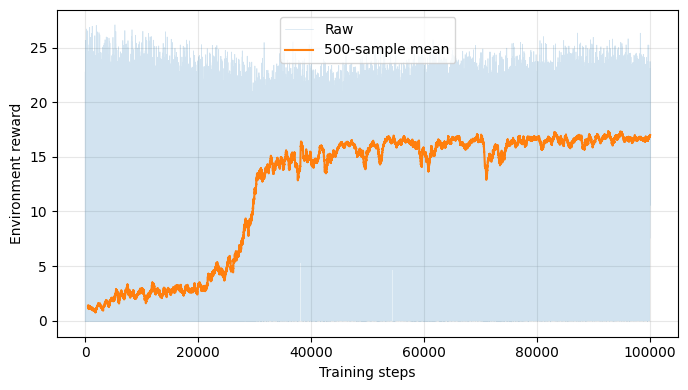

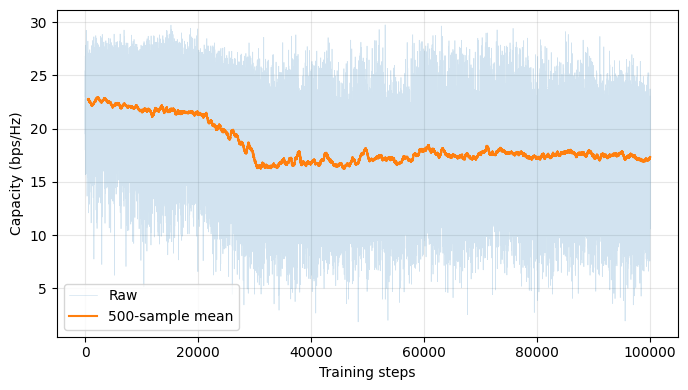

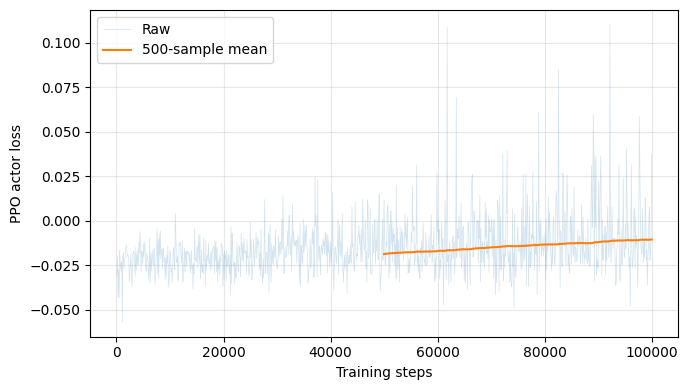

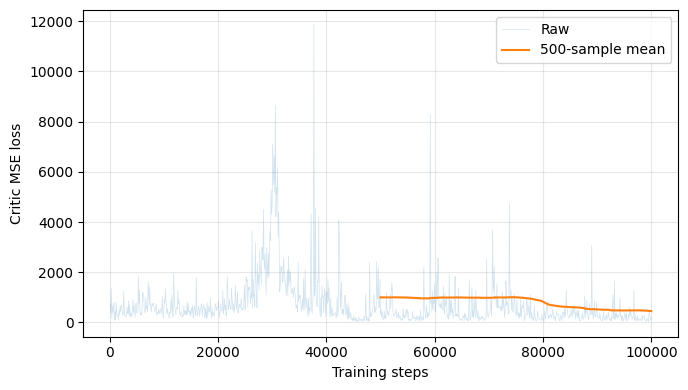

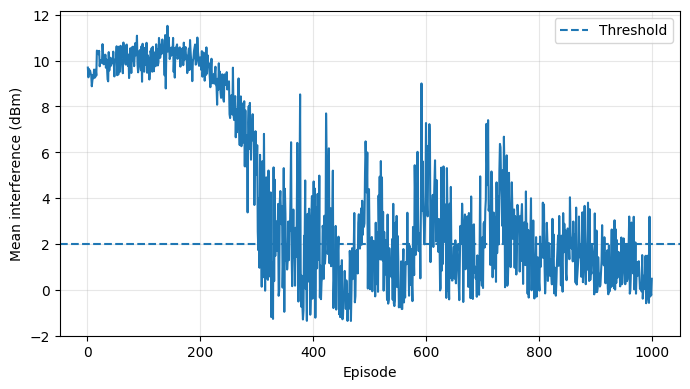

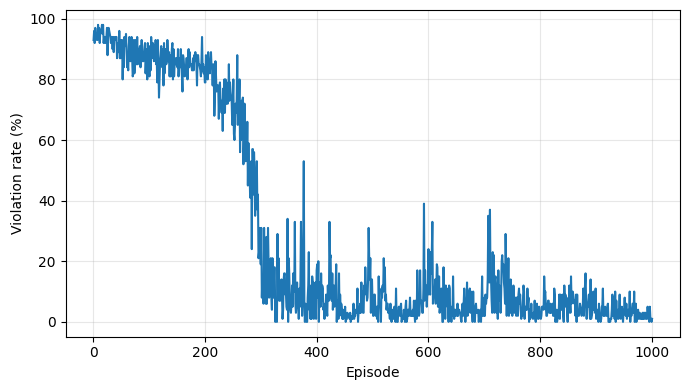

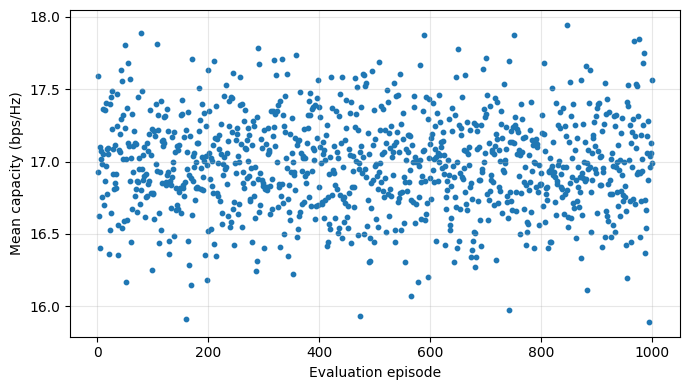

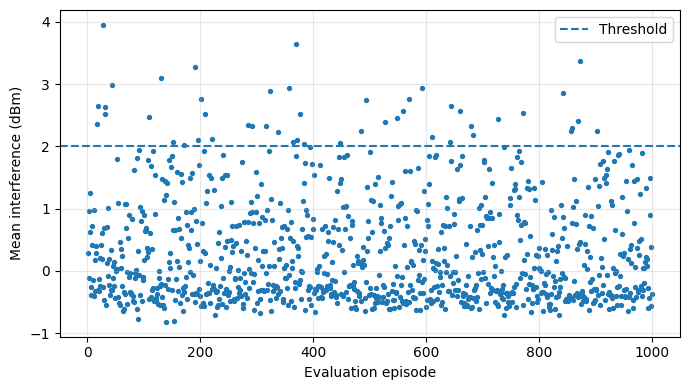

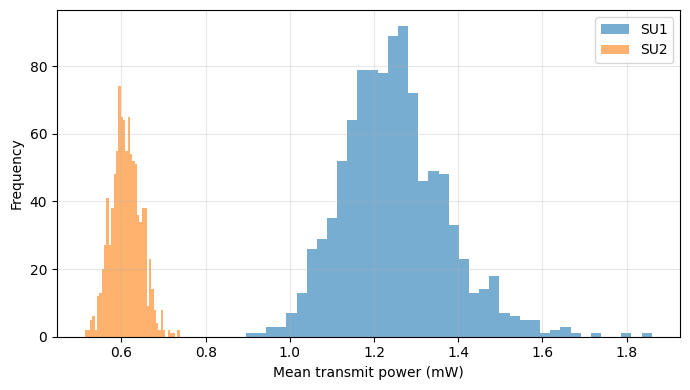

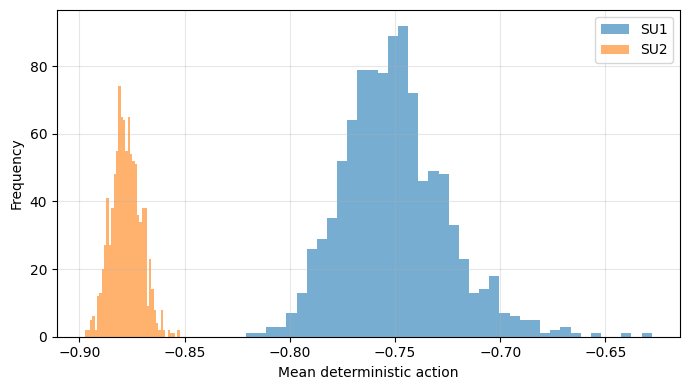


                 PPO RESULTS

Training steps: 100000
Training time: 130.20 seconds

TRAINING
Mean reward: 12.1454
Mean capacity: 18.4552 bps/Hz
Mean interference: 5.9424 dBm
Violation rate: 29.06%
Mean total power: 3.7788 mW

PPO CONFIGURATION
Gamma: 0.99
GAE lambda: 0.95
Clipping parameter: 0.2
Optimization epochs: 10
Action standard deviation: 0.2

EVALUATION
Mean reward: 16.5771
Mean capacity: 16.9828 +/- 0.3308 bps/Hz
Mean interference: 0.3966 dBm
Threshold: 2.00 dBm
Violation rate: 1.99%
Constraint satisfaction: 98.01%
SU1 mean power: 1.2489 mW
SU2 mean power: 0.6108 mW
SU1 mean action: -0.7502
SU2 mean action: -0.8778
Execution time: 0.3303 ms/action

Saved results to:
/content/ppo_5d


In [ ]:
from pathlib import Path
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
from utils import *


N_ST = 2

MAX_POWER_MW = 10.0
NOISE_POWER_MW = 1e-3
ITH_DBM = 2.0

MAX_POWER = MAX_POWER_MW * 1e-3
N0 = NOISE_POWER_MW * 1e-3
ITH_DBW = ITH_DBM - 30.0

STEPS_PER_RUN = 100


NUM_EPISODES = 1000
TOTAL_TRAINING_STEPS = NUM_EPISODES * STEPS_PER_RUN

ACTOR_LR = 1e-3
CRITIC_LR = 1e-3

GAMMA = 0.99
GAE_LAMBDA = 0.95

EPS_CLIP = 0.2
K_EPOCHS = 10


ACTION_STD = 0.2

ROLLOUT_STEPS = 128

EVAL_EPISODES = 1000
EVAL_SEED_OFFSET = 100_000

SMOOTH_WINDOW = 500

seed = 0

OUTPUT_DIR = Path("ppo_5d")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


torch.manual_seed(seed)
np.random.seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)



env = CRNetwork(
    n_ST=N_ST,
    noise=N0,
    int_thresh=ITH_DBW,
    max_power=MAX_POWER,
    steps_per_run=STEPS_PER_RUN,
    dtype=np.float32,
    seed=seed,
    alpha=1.0,
    error_variance = 0.0
)



expected_ith_w = dbm_to_watts(ITH_DBM)

assert np.isclose(env.Ith, expected_ith_w, rtol=1e-6)
assert np.isclose(env.N0, N0)
assert np.isclose(env.Pmax, MAX_POWER)

STATE_DIM = env.observation_space.shape[0]
ACTION_DIM = env.action_space.shape[0]

assert STATE_DIM == 5, f"Expected 5 states, got {STATE_DIM}"
assert ACTION_DIM == 2, f"Expected 2 actions, got {ACTION_DIM}"

assert ROLLOUT_STEPS > 0
assert STEPS_PER_RUN > 0

print("\n========== PPO ENVIRONMENT CONFIGURATION ==========")
print(f"Secondary pairs       : {N_ST}")
print(f"State dimension       : {STATE_DIM}")
print(f"Action dimension      : {ACTION_DIM}")
print(f"Maximum power         : {MAX_POWER_MW:.2f} mW per SU")
print(f"Noise power           : {N0:.6e} W")
print(f"Interference threshold: {ITH_DBM:.2f} dBm")
print(f"Training steps        : {TOTAL_TRAINING_STEPS}")
print(f"Rollout length        : {ROLLOUT_STEPS}")
print(f"CSI error variance    : {env.error_variance}")
print(f"Discount factor       : {GAMMA}")
print(f"GAE lambda            : {GAE_LAMBDA}")
print(f"PPO clipping          : {EPS_CLIP}")
print(f"PPO epochs            : {K_EPOCHS}")
print(f"Action standard dev.  : {ACTION_STD}")
print("===================================================\n")






# ============================================================
# 10. INITIALIZE PPO
# ============================================================

ppo_agent = PPO(
    state_dim=STATE_DIM,
    action_dim=ACTION_DIM,
    actor_lr=ACTOR_LR,
    critic_lr=CRITIC_LR,
    gamma=GAMMA,
    gae_lambda=GAE_LAMBDA,
    eps_clip=EPS_CLIP,
    K_epochs=K_EPOCHS,
    action_std=ACTION_STD,
    device=None
)

training_device = next(
    ppo_agent.actor.parameters()
).device

print("Training device:", training_device)


# ============================================================
# 11. HISTORY ARRAYS
# ============================================================

step_numbers = []
step_rewards = []
step_capacities = []

step_powers = []
step_total_power = []

step_violations = []
step_actions = []

step_interference_w = []

episode_interference_w = []
episode_interference_dbm = []
episode_violation_rate = []
episode_reward = []
episode_capacity = []

actor_losses = []
critic_losses = []
loss_steps = []

total_time = 0


# ============================================================
# 12. TRAINING LOOP
# ============================================================

if training_device.type == "cuda":
    torch.cuda.synchronize(training_device)

start_time = time.perf_counter()

for episode in range(NUM_EPISODES):

    obs, _ = env.reset(seed=seed + episode)

    obs = prep_obs(
        obs,
        env.Pmax,
        N_ST
    )

    ep_interference_sum = 0.0
    ep_violations = 0
    ep_reward_sum = 0.0
    ep_capacity_sum = 0.0

    for j in range(STEPS_PER_RUN):

        if len(ppo_agent.buffer.rewards) == 0:
          update_action_std_schedule(ppo_agent, total_time / TOTAL_TRAINING_STEPS)

        # --------------------------------------------
        # SELECT ACTION
        # --------------------------------------------

        action, raw_action, logprob = ppo_agent.choose_action(
            obs,
            deterministic=False
        )

        action = np.asarray(
            action,
            dtype=np.float32
        )

        # --------------------------------------------
        # ENVIRONMENT STEP
        # --------------------------------------------

        next_obs, reward, terminated, truncated, info = env.step(
            action.copy()
        )

        next_obs = prep_obs(
            next_obs,
            env.Pmax,
            N_ST
        )

        reward = float(reward)

        capacity = np.asarray(
            info["capacity"],
            dtype=np.float64
        )

        powers_w = step_powers_w(
            info,
            action,
            env
        )

        interference_w = float(info["interference"])

        # Actual interference determines violations
        violated = bool(interference_w > env.Ith)

        # --------------------------------------------
        # RECORD STEP STATISTICS
        # --------------------------------------------

        total_time += 1

        step_numbers.append(total_time)
        step_rewards.append(reward)
        step_capacities.append(float(capacity.sum()))

        step_powers.append(powers_w.copy())
        step_total_power.append(float(powers_w.sum()))

        step_violations.append(int(violated))
        step_actions.append(action.copy())

        step_interference_w.append(interference_w)

        # --------------------------------------------
        # EPISODE STATISTICS
        # --------------------------------------------

        ep_interference_sum += interference_w
        ep_violations += int(violated)
        ep_reward_sum += reward
        ep_capacity_sum += float(capacity.sum())

        # --------------------------------------------
        # STORE TRANSITION IN PPO
        # --------------------------------------------

        ppo_agent.remember(
            obs,
            raw_action,
            logprob,
            reward,
            next_obs,
            terminated,
            truncated
        )

        obs = next_obs

        # --------------------------------------------
        # PPO UPDATE
        # --------------------------------------------

        rollout_complete = (
            len(ppo_agent.buffer.rewards) >= ROLLOUT_STEPS
        )

        episode_complete = bool(terminated or truncated)

        if rollout_complete or episode_complete:

            losses = ppo_agent.update()

            if losses is not None:

                actor_losses.append(float(losses[0]))
                critic_losses.append(float(losses[1]))

                loss_steps.append(total_time)

        if episode_complete:
            break

    # --------------------------------------------
    # EPISODE SUMMARIES
    # --------------------------------------------

    steps_done = j + 1

    mean_interference = ep_interference_sum / steps_done

    episode_interference_w.append(mean_interference)

    episode_interference_dbm.append(
        float(watts_to_dbm(mean_interference))
    )

    episode_violation_rate.append(
        ep_violations / steps_done
    )

    episode_reward.append(
        ep_reward_sum / steps_done
    )

    episode_capacity.append(
        ep_capacity_sum / steps_done
    )

    # --------------------------------------------
    # PROGRESS DISPLAY
    # --------------------------------------------

    if episode % 10 == 0 or episode == NUM_EPISODES - 1:

        recent = min(10, len(episode_reward))

        print(
            f"Episode {episode + 1:4d}/{NUM_EPISODES} | "
            f"Steps {total_time:6d} | "
            f"Reward {episode_reward[-1]:8.4f} | "
            f"Capacity {episode_capacity[-1]:8.4f} | "
            f"Interference {episode_interference_dbm[-1]:8.3f} dBm | "
            f"Violations {100 * episode_violation_rate[-1]:6.2f}% | "
            f"Recent reward {np.mean(episode_reward[-recent:]):8.4f} | "
            f"Recent capacity {np.mean(episode_capacity[-recent:]):8.4f}"
        )


if training_device.type == "cuda":
    torch.cuda.synchronize(training_device)

training_seconds = time.perf_counter() - start_time


# ============================================================
# 13. DETERMINISTIC EVALUATION
# ============================================================

def evaluate(agent, env, episodes, seed0):

    capacities = []
    interferences_w = []
    violation_rates = []
    rewards = []

    powers = []
    actions_history = []

    action_seconds = 0.0
    action_calls = 0

    agent.actor.eval()
    agent.critic.eval()

    for e in range(episodes):

        obs, _ = env.reset(seed=seed0 + e)

        obs = prep_obs(
            obs,
            env.Pmax,
            N_ST
        )

        ep_capacity = 0.0
        ep_interference = 0.0
        ep_violations = 0
        ep_reward = 0.0

        ep_powers = []
        ep_actions = []

        for j in range(STEPS_PER_RUN):

            t0 = time.perf_counter()

            action, raw_action, logprob = agent.choose_action(
                obs,
                deterministic=True
            )

            action_seconds += time.perf_counter() - t0
            action_calls += 1

            action = np.asarray(
                action,
                dtype=np.float32
            )

            next_obs, reward, terminated, truncated, info = env.step(
                action.copy()
            )

            next_obs = prep_obs(
                next_obs,
                env.Pmax,
                N_ST
            )

            ep_capacity += float(
                np.sum(info["capacity"])
            )

            ep_interference += float(
                info["interference"]
            )

            ep_violations += int(
                float(info["interference"]) > env.Ith
            )

            ep_reward += float(reward)

            ep_powers.append(
                step_powers_w(info, action, env)
            )

            ep_actions.append(action.copy())

            obs = next_obs

            if terminated or truncated:
                break

        n = j + 1

        capacities.append(ep_capacity / n)
        interferences_w.append(ep_interference / n)
        violation_rates.append(ep_violations / n)
        rewards.append(ep_reward / n)

        powers.append(
            np.mean(ep_powers, axis=0)
        )

        actions_history.append(
            np.mean(ep_actions, axis=0)
        )

    ms_per_action = (
        1000.0 * action_seconds / max(action_calls, 1)
    )

    return (
        np.asarray(capacities),
        np.asarray(interferences_w),
        np.asarray(violation_rates),
        np.asarray(rewards),
        np.asarray(powers),
        np.asarray(actions_history),
        ms_per_action
    )


(
    eval_capacity,
    eval_interference_w,
    eval_violation,
    eval_reward,
    eval_powers,
    eval_actions,
    ms_per_action
) = evaluate(
    ppo_agent,
    env,
    EVAL_EPISODES,
    EVAL_SEED_OFFSET
)

eval_interference_dbm = watts_to_dbm(
    eval_interference_w
)


# ============================================================
# 14. SAVE MODEL AND HISTORY
# ============================================================

np.savez_compressed(
    OUTPUT_DIR / "ppo_training_history_paper.npz",

    steps=step_numbers,
    rewards=step_rewards,
    capacity=step_capacities,

    powers_w=step_powers,
    total_power_w=step_total_power,

    violations=step_violations,
    actions=step_actions,
    interference_w=step_interference_w,

    episode_interference_w=episode_interference_w,
    episode_interference_dbm=episode_interference_dbm,
    episode_violation_rate=episode_violation_rate,
    episode_reward=episode_reward,
    episode_capacity=episode_capacity,

    loss_steps=loss_steps,
    actor_loss=actor_losses,
    critic_loss=critic_losses,

    eval_capacity=eval_capacity,
    eval_interference_w=eval_interference_w,
    eval_interference_dbm=eval_interference_dbm,
    eval_violation_rate=eval_violation,
    eval_reward=eval_reward,
    eval_powers=eval_powers,
    eval_actions=eval_actions,

    ms_per_action=ms_per_action,

    pmax_w=env.Pmax,
    noise_w=env.N0,
    threshold_w=env.Ith,
    threshold_dbm=ITH_DBM,
    threshold_dbw=ITH_DBW,

    gamma=GAMMA,
    gae_lambda=GAE_LAMBDA,
    actor_lr=ACTOR_LR,
    critic_lr=CRITIC_LR,
    eps_clip=EPS_CLIP,
    K_epochs=K_EPOCHS,
    action_std=ACTION_STD,
    rollout_steps=ROLLOUT_STEPS,

    seed=seed,
    training_seconds=training_seconds
)

ppo_agent.save(
    OUTPUT_DIR / "ppo_weights.pt"
)


# ============================================================
# 15. PLOTTING HELPERS
# ============================================================

def save_fig(fig, name):

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / f"{name}.png",
        dpi=300
    )

    fig.savefig(
        OUTPUT_DIR / f"{name}.pdf"
    )

    plt.show()
    plt.close(fig)


def plot_curve(x, values, ylabel, filename):

    x = np.asarray(x)
    values = np.asarray(values, dtype=np.float64)

    if len(values) == 0:
        print(f"Skipping {filename}: no data.")
        return

    window = min(SMOOTH_WINDOW, len(values))

    cumulative = np.concatenate(
        ([0.0], np.cumsum(values))
    )

    smoothed = (
        cumulative[window:] - cumulative[:-window]
    ) / window

    fig, ax = plt.subplots(figsize=(7, 4))

    ax.plot(
        x,
        values,
        alpha=0.2,
        linewidth=0.5,
        label="Raw"
    )

    ax.plot(
        x[window - 1:],
        smoothed,
        linewidth=1.5,
        label=f"{window}-sample mean"
    )

    ax.set_xlabel("Training steps")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.legend()

    save_fig(fig, filename)


# ============================================================
# 16. TRAINING PLOTS
# ============================================================

plot_curve(
    step_numbers,
    step_rewards,
    "Environment reward",
    "reward"
)

plot_curve(
    step_numbers,
    step_capacities,
    "Capacity (bps/Hz)",
    "capacity"
)

plot_curve(
    loss_steps,
    actor_losses,
    "PPO actor loss",
    "actor_loss"
)

plot_curve(
    loss_steps,
    critic_losses,
    "Critic MSE loss",
    "critic_loss"
)


# ============================================================
# 17. INTERFERENCE AND VIOLATION PLOTS
# ============================================================

episodes_axis = np.arange(
    1,
    NUM_EPISODES + 1
)

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    episodes_axis,
    episode_interference_dbm
)

ax.axhline(
    ITH_DBM,
    linestyle="--",
    label="Threshold"
)

ax.set_xlabel("Episode")
ax.set_ylabel("Mean interference (dBm)")
ax.grid(alpha=0.3)
ax.legend()

save_fig(fig, "training_interference")


fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    episodes_axis,
    100 * np.asarray(episode_violation_rate)
)

ax.set_xlabel("Episode")
ax.set_ylabel("Violation rate (%)")
ax.grid(alpha=0.3)

save_fig(fig, "training_violations")


# ============================================================
# 18. EVALUATION PLOTS
# ============================================================

eval_runs = np.arange(
    1,
    EVAL_EPISODES + 1
)

fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(
    eval_runs,
    eval_capacity,
    s=10
)

ax.set_xlabel("Evaluation episode")
ax.set_ylabel("Mean capacity (bps/Hz)")
ax.grid(alpha=0.3)

save_fig(fig, "evaluation_capacity")


fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(
    eval_runs,
    eval_interference_dbm,
    s=8
)

ax.axhline(
    ITH_DBM,
    linestyle="--",
    label="Threshold"
)

ax.set_xlabel("Evaluation episode")
ax.set_ylabel("Mean interference (dBm)")
ax.grid(alpha=0.3)
ax.legend()

save_fig(fig, "evaluation_interference")


fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(
    eval_powers[:, 0] * 1000,
    bins=40,
    alpha=0.6,
    label="SU1"
)

ax.hist(
    eval_powers[:, 1] * 1000,
    bins=40,
    alpha=0.6,
    label="SU2"
)

ax.set_xlabel("Mean transmit power (mW)")
ax.set_ylabel("Frequency")
ax.grid(alpha=0.3)
ax.legend()

save_fig(fig, "evaluation_power")


fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(
    eval_actions[:, 0],
    bins=40,
    alpha=0.6,
    label="SU1"
)

ax.hist(
    eval_actions[:, 1],
    bins=40,
    alpha=0.6,
    label="SU2"
)

ax.set_xlabel("Mean deterministic action")
ax.set_ylabel("Frequency")
ax.grid(alpha=0.3)
ax.legend()

save_fig(fig, "evaluation_actions")


# ============================================================
# 19. FINAL SUMMARY
# ============================================================

mean_train_interference_w = np.mean(
    step_interference_w
)

mean_eval_interference_w = np.mean(
    eval_interference_w
)

print("\n==============================================")
print("                 PPO RESULTS")
print("==============================================")

print(f"\nTraining steps: {total_time}")
print(f"Training time: {training_seconds:.2f} seconds")

print("\nTRAINING")

print(f"Mean reward: {np.mean(step_rewards):.4f}")
print(f"Mean capacity: {np.mean(step_capacities):.4f} bps/Hz")

print(
    f"Mean interference: "
    f"{float(watts_to_dbm(mean_train_interference_w)):.4f} dBm"
)

print(
    f"Violation rate: "
    f"{100 * np.mean(step_violations):.2f}%"
)

print(
    f"Mean total power: "
    f"{np.mean(step_total_power) * 1000:.4f} mW"
)

print("\nPPO CONFIGURATION")

print(f"Gamma: {GAMMA}")
print(f"GAE lambda: {GAE_LAMBDA}")
print(f"Clipping parameter: {EPS_CLIP}")
print(f"Optimization epochs: {K_EPOCHS}")
print(f"Action standard deviation: {ACTION_STD}")

print("\nEVALUATION")

print(f"Mean reward: {eval_reward.mean():.4f}")

print(
    f"Mean capacity: {eval_capacity.mean():.4f} "
    f"+/- {eval_capacity.std():.4f} bps/Hz"
)

print(
    f"Mean interference: "
    f"{float(watts_to_dbm(mean_eval_interference_w)):.4f} dBm"
)

print(f"Threshold: {ITH_DBM:.2f} dBm")

print(
    f"Violation rate: "
    f"{100 * eval_violation.mean():.2f}%"
)

print(
    f"Constraint satisfaction: "
    f"{100 * (1 - eval_violation.mean()):.2f}%"
)

print(
    f"SU1 mean power: "
    f"{eval_powers[:, 0].mean() * 1000:.4f} mW"
)

print(
    f"SU2 mean power: "
    f"{eval_powers[:, 1].mean() * 1000:.4f} mW"
)

print(
    f"SU1 mean action: {eval_actions[:, 0].mean():.4f}"
)

print(
    f"SU2 mean action: {eval_actions[:, 1].mean():.4f}"
)

print(f"Execution time: {ms_per_action:.4f} ms/action")

print("\nSaved results to:")
print(OUTPUT_DIR.resolve())

print("==============================================")
